# Tome 15, Chapter 8: Heuristics that predict (Python companion)

Sums of three cubes, by computer: the famous identities checked exactly, the local obstructions (Proposition 5.1, Exercise 5.1), the local densities of Proposition 5.3 and their surprising pattern at primes $p\equiv1\pmod3$, the constant $\sigma_\infty$ of the heuristic, and two searches: the naive one, and Booker's divisor trick (Proposition 5.4, Corollary 5.5). The computer-science application is the search itself: **from $O(B^2)$ to almost $O(B)$ by changing the parametrisation**, with a hash table and modular square roots doing the rest. Exercises first, solutions at the end. Requires `numpy`, `sympy` and `mpmath`.

In [1]:
import math, numpy as np, mpmath as mp
from sympy import primerange, isprime
from math import isqrt
def icbrt(n):
    # exact integer cube root (floor), for integers of any size
    s = -1 if n < 0 else 1; n = abs(n)
    r = int(round(n ** (1/3))) if n < 2**1000 else 1 << (n.bit_length() // 3)
    while r**3 > n: r -= 1
    while (r+1)**3 <= n: r += 1
    return s * r

## Exercises

**P8.1 (★) The identities.** Check the four lines of identities at the start of the chapter and the third representation of $3$, in exact integer arithmetic. Check the two families of Proposition 5.2 for $|t|\le100$.

**P8.2 (★) Local obstructions.** For every modulus $m\le200$, list the residues modulo $m$ that are not sums of three cubes. Check that an obstruction occurs exactly when $9\mid m$, and that it always comes from $n\equiv\pm4\pmod9$ (Exercise 5.1).

**P8.3 (★★) Local densities.** Compute the ratio of Proposition 5.3 modulo $p^k$ for small $p^k$, and check part (a). Then, for primes $p\equiv1\pmod3$ up to $1000$ and $p\nmid3n$, compute $p(\sigma_p(n)-1)$ for $n=3$ and $n=2$, and colour by whether $n$ is a cube modulo $p$. What do you see?

**P8.4 (★) The real density.** Compute $4\int_1^\infty(t^3+1)^{-2/3}\,\mathrm dt$ numerically and compare with $\frac{2\Gamma(1/3)^2}{3\Gamma(2/3)}$ (Exercise 5.6).

**P8.5 (★★) The naive search.** Using a sorted table of the values $x^3+y^3$, find all representations of $n$ with $|n|\le100$ and $\max(|x|,|y|,|z|)\le1000$. Which $n\not\equiv\pm4\pmod9$ get no solution? Compare with the counts predicted by the logarithmic law: do the solutions of $n=2$ (Proposition 5.2) and $n=3$ fill the scales evenly?

**P8.6 (★★) Booker's search.** Implement Corollary 5.5: for each $d$ and each $z$ with $|z|\le B$ and $z^3\equiv n\pmod{|d|}$, test whether $\Delta$ is a square. Run it with $B=300$ for $n\le100$, check that it finds everything the naive search finds with smallest coordinate $\le300$, and list the solutions it finds whose largest coordinate is beyond the reach of the naive search. Count the pairs $(d,z)$ examined.

**P8.7 (★) The solution for 33.** Do Exercise 5.5.

## Solutions

**P8.1.** Python integers are exact, so this is one line each.

In [2]:
ids = {3: [(1,1,1), (4,4,-5), (569936821221962380720, -569936821113563493509, -472715493453327032)],
       30: [(2220422932, -2218888517, -283059965)],
       33: [(8866128975287528, -8778405442862239, -2736111468807040)],
       42: [(-80538738812075974, 80435758145817515, 12602123297335631)]}
for n, sols in ids.items():
    for s in sols:
        print(n, sum(v**3 for v in s) == n, s)
fam = all((1+6*t**3)**3 + (1-6*t**3)**3 + (-6*t**2)**3 == 2 and
          (9*t**4)**3 + (3*t-9*t**4)**3 + (1-9*t**3)**3 == 1 for t in range(-100, 101))
print('families hold for |t| <= 100:', fam)

3 True (1, 1, 1)
3 True (4, 4, -5)
3 True (569936821221962380720, -569936821113563493509, -472715493453327032)
30 True (2220422932, -2218888517, -283059965)
33 True (8866128975287528, -8778405442862239, -2736111468807040)
42 True (-80538738812075974, 80435758145817515, 12602123297335631)
families hold for |t| <= 100: True


**P8.2.** The set of sums of three cubes modulo $m$ is a triple sumset of the set of cubes.

In [3]:
def missing(m):
    C = {pow(x, 3, m) for x in range(m)}
    S2 = {(a+b) % m for a in C for b in C}
    S3 = {(a+b) % m for a in S2 for b in C}
    return sorted(set(range(m)) - S3)
bad = {m: missing(m) for m in range(2, 201)}
obst = [m for m in bad if bad[m]]
print('moduli with an obstruction:', obst[:12], '...')
print('all multiples of 9:', all(m % 9 == 0 for m in obst), '| every multiple of 9 obstructs:', all(bad[m] for m in range(9, 201, 9)))
print('missing residues are exactly n = +-4 mod 9:', all(set(bad[m]) == {r for r in range(m) if r % 9 in (4, 5)} for m in obst))

moduli with an obstruction: [9, 18, 27, 36, 45, 54, 63, 72, 81, 90, 99, 108] ...
all multiples of 9: True | every multiple of 9 obstructs: True
missing residues are exactly n = +-4 mod 9: True


Exactly as in Exercise 5.1: modulo primes $p\ne3$ there is nothing (Cauchy–Davenport and lifting), and modulo powers of $3$ nothing beyond what $9$ already sees.

**P8.3.** Counting solutions modulo $m$ by brute force over $m^3$ triples is too slow; instead count how often each residue is a cube and convolve, which costs $O(m^2)$.

In [4]:
def count(n, m):
    c = np.bincount([pow(x, 3, m) for x in range(m)], minlength=m).astype(np.int64)
    idx = np.arange(m)
    c2 = np.zeros(m, dtype=np.int64)
    for a in np.nonzero(c)[0]:
        c2[(a + idx) % m] += c[a] * c
    return int(sum(c2[(n - r) % m] * c[r] for r in np.nonzero(c)[0]))
for p in (2, 5, 11, 3, 7, 13):
    for n in (2, 3, 4):
        row = [count(n, p**k) / p**(2*k) for k in (1, 2, 3) if p**k <= 400]
        print(f'p={p:2d} n={n}:', ' '.join(f'{v:.4f}' for v in row))

p= 2 n=2: 1.0000 0.7500 0.7500
p= 2 n=3: 1.0000 1.0000 1.0000
p= 2 n=4: 1.0000 1.2500 0.7500
p= 5 n=2: 1.0000 1.0000 1.0000
p= 5 n=3: 1.0000 1.0000 1.0000
p= 5 n=4: 1.0000 1.0000 1.0000
p=11 n=2: 1.0000 1.0000
p=11 n=3: 1.0000 1.0000
p=11 n=4: 1.0000 1.0000
p= 3 n=2: 1.0000 1.0000 1.0000
p= 3 n=3: 1.0000 0.3333 0.3333
p= 3 n=4: 1.0000 0.0000 0.0000
p= 7 n=2: 0.5510 0.5510 0.5510
p= 7 n=3: 0.5510 0.5510 0.5510
p= 7 n=4: 0.5510 0.5510 0.5510
p=13 n=2: 0.7988 0.7988
p=13 n=3: 0.7988 0.7988
p=13 n=4: 0.7988 0.7988


For $p=2,5,11$ (all $\equiv2\pmod3$) and $p\nmid n$ the ratio is exactly $1$ at every level, as Proposition 5.3(a) says; for $p=2$, $n=2,4$ it is not ($p\mid n$, outside the proposition). For $p=3$ and $n=4$ the ratio drops to $0$ from $k=2$ on, part (b). For $p=7,13$ the ratio is not $1$ but is stable in $k$ when $p\nmid n$, because the lifting argument still works. Now the pattern at $p\equiv1\pmod3$:

n=3: cube: 5.87 to 6.12; non-cube: -3.37 to -2.62; fraction of cubes 0.325
n=2: cube: 5.87 to 6.19; non-cube: -3.37 to -2.62; fraction of cubes 0.300


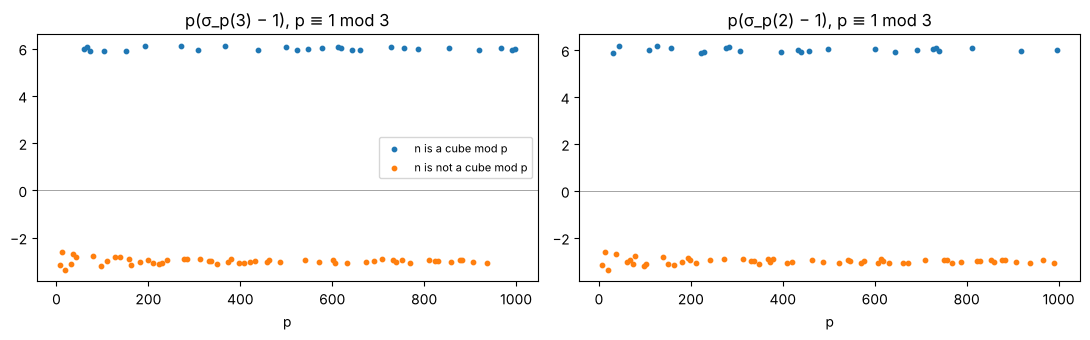

In [5]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, n in zip(axes, (3, 2)):
    P = [p for p in primerange(5, 1000) if p % 3 == 1 and n % p]
    val = [p * (count(n, p) / p**2 - 1) for p in P]
    cube = [pow(n, (p-1)//3, p) == 1 for p in P]
    ax.scatter([p for p, c in zip(P, cube) if c], [v for v, c in zip(val, cube) if c], s=10, label='n is a cube mod p')
    ax.scatter([p for p, c in zip(P, cube) if not c], [v for v, c in zip(val, cube) if not c], s=10, label='n is not a cube mod p')
    ax.axhline(0, color='grey', lw=.5); ax.set_title(f'p(σ_p({n}) − 1), p ≡ 1 mod 3'); ax.set_xlabel('p')
    print(f'n={n}: cube: {min(v for v,c in zip(val,cube) if c):.2f} to {max(v for v,c in zip(val,cube) if c):.2f};',
          f'non-cube: {min(v for v,c in zip(val,cube) if not c):.2f} to {max(v for v,c in zip(val,cube) if not c):.2f};',
          f'fraction of cubes {np.mean(cube):.3f}')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

Two bands, around $6$ and around $-3$, with a spread that shrinks as $p$ grows. (Explaining the bands is a nice exercise with cubic Jacobi sums: the count modulo $p$ is $p^2$ plus a sum of terms $\chi(n)J$, and the Jacobi sums of three cubic characters have absolute value $p$ or $\sqrt p$.) About a third of the primes see $n$ as a cube, so the average correction $\frac13\cdot6+\frac23\cdot(-3)$ vanishes: this is why $\prod_p\sigma_p(n)$ converges at all.

**P8.4.**

In [6]:
mp.mp.dps = 30
I = 4 * mp.quad(lambda t: (t**3 + 1) ** (-mp.mpf(2)/3), [1, mp.inf])
G = 2 * mp.gamma(mp.mpf(1)/3)**2 / (3 * mp.gamma(mp.mpf(2)/3))
print(I); print(G)

3.5332775005708999146273789993
3.5332775005708999146273789993


**P8.5.** Sort all $s=x^3+y^3$ with $|x|,|y|\le B$; for each $z$, the $n$ in $[-100,100]$ with $n=s+z^3$ correspond to the $s$ in a window around $-z^3$, found by binary search. Values are below $2\cdot10^9$, so 64-bit integers are exact. This is the naive $O(B^2\log B)$ search.

In [7]:
B, M = 1000, 100
xs = np.arange(-B, B+1, dtype=np.int64)
X, Y = np.meshgrid(xs, xs, indexing='ij'); mask = X <= Y
X, Y = X[mask], Y[mask]; S = X**3 + Y**3
order = np.argsort(S); S, X, Y = S[order], X[order], Y[order]
sols = {}
for z in range(-B, B+1):
    z3 = z**3
    lo, hi = np.searchsorted(S, -z3 - M), np.searchsorted(S, -z3 + M, side='right')
    for i in range(lo, hi):
        t = tuple(sorted((int(X[i]), int(Y[i]), z)))
        sols.setdefault(int(S[i]) + z3, set()).add(t)
cand = [n for n in range(1, M+1) if n % 9 not in (4, 5)]
print('n <= 100, not +-4 mod 9, with no solution with max <= 1000:', [n for n in cand if n not in sols])
print('number of solutions (up to order) for n = 2, 3:', len(sols[2]), len(sols[3]))

n <= 100, not +-4 mod 9, with no solution with max <= 1000: [30, 33, 39, 42, 52, 74, 75, 84, 87]
number of solutions (up to order) for n = 2, 3: 6 2


Nine values of $n$ get nothing: $30, 33, 39, 42, 52, 74, 75, 84, 87$. Among them are $30$, $33$ and $42$, whose smallest solutions have ten, sixteen and seventeen digits. For $n=2$, all the solutions found come from the first family of Proposition 5.2 (with $t=0,\dots,5$); for $n=3$, there are only the two classical ones. That is the logarithmic law at work: $\rho(n)\log B$ with $\rho(n)$ of order $1$ means a handful of solutions per factor $e$ in scale, and nothing forces any of them to be small.

In [8]:
fam2 = {tuple(sorted((1+6*t**3, 1-6*t**3, -6*t**2))) for t in range(-10, 11)}
print('n=2 solutions:', sorted(sols[2], key=lambda s: max(map(abs, s))))
print('not from the family:', [s for s in sols[2] if s not in fam2])
print('n=3 solutions:', sols[3])

n=2 solutions: [(0, 1, 1), (-6, -5, 7), (-47, -24, 49), (-161, -54, 163), (-383, -96, 385), (-749, -150, 751)]
not from the family: []
n=3 solutions: {(1, 1, 1), (-5, 4, 4)}


**P8.6.** For each $d$ we need the $z$ modulo $|d|$ with $z^3\equiv n$. Brute force over residues is enough for this size. The test is Proposition 5.4: $3d\mid4(n-z^3)-d^3$, $\Delta\ge0$ a square, $d\pm\sqrt\Delta$ even.

In [9]:
def booker(n, B):
    found, pairs = set(), 0
    D = icbrt(4*abs(n) + 4*B**3) + 1
    for d in range(1, D + 1):
        roots = [r for r in range(d) if (r**3 - n) % d == 0]
        for r in roots:
            for z in range(r - ((r + B) // d) * d, B + 1, d):
                if z < -B: continue
                pairs += 1
                for dd in (d, -d):
                    num = 4*(n - z**3) - dd**3
                    if num % (3*dd): continue
                    Dl = num // (3*dd)
                    if Dl < 0: continue
                    q = isqrt(Dl)
                    if q*q != Dl or (dd + q) % 2: continue
                    x, y = (dd + q)//2, (dd - q)//2
                    assert x**3 + y**3 + z**3 == n
                    found.add(tuple(sorted((x, y, z))))
    return found, pairs
B2 = 300
tot, new = 0, {}
for n in cand:
    if round(n ** (1/3)) ** 3 == n: continue      # cubes excluded
    f, pairs = booker(n, B2); tot += pairs
    naive = {s for s in sols.get(n, set()) if min(map(abs, s)) <= B2}
    assert naive <= f, n
    big = [s for s in f if max(map(abs, s)) > B]
    if big: new[n] = big
print('pairs (d, z) examined over all n:', tot)
for n, b in new.items(): print(n, b)

pairs (d, z) examined over all n: 290725
2 [(-2057, -294, 2059), (-1295, -216, 1297)]
16 [(-1498, -300, 1502)]
26 [(-2107, 237, 2106)]
28 [(-2268, -249, 2269)]
34 [(-1555, -244, 1557)]
54 [(-1149, -288, 1155)]
60 [(-1201, -163, 1202)]


Every solution of the naive search with smallest coordinate at most $300$ is recovered, and Booker's search also finds solutions whose largest coordinate is beyond $1000$, out of reach of the naive table, at a cost proportional to $B$ (times a logarithmic factor) per value of $n$ instead of $B^2$. The two new solutions for $n=2$ are the family members $t=6,7$, those for $n=16=2\cdot2^3$ and $n=54=2\cdot3^3$ are $2$ and $3$ times solutions for $n=2$ (Exercise 5.4); those for $26$, $28$, $34$ and $60$ come from no family. The real searches used $B$ around $10^{16}$ to $10^{17}$, a sieve on $z$ and many further refinements.

**P8.7.**

In [10]:
x, y, z = 8866128975287528, -8778405442862239, -2736111468807040
d = x + y
print('d =', d, '| d divides 33 - z^3:', (33 - z**3) % d == 0)
Dl = (4*(33 - z**3) - d**3) // (3*d); q = isqrt(Dl)
print('Delta is a square:', q*q == Dl, '| x - y =', q)
print('recovered:', ((d + q)//2, (d - q)//2) == (x, y))
print('|z| / d =', abs(z) / d, '| bound (4|33 - z^3|)^(1/3) / d =', icbrt(4*abs(33 - z**3)) / d)

d = 87723532425289 | d divides 33 - z^3: True
Delta is a square: True | x - y = 17644534418149767
recovered: True
|z| / d = 31.190165206095507 | bound (4|33 - z^3|)^(1/3) / d = 49.511301059217935


So $d=87\,723\,532\,425\,289$, about $31$ times smaller than $|z|$ and about $50$ times smaller than the bound of Corollary 5.5.